<a href="https://colab.research.google.com/github/HebaRouk/-Build-a-ML-Workflow-For-Scones-Unlimited-On-Amazon-SageMaker/blob/main/CV_TASK1_ASS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ===== Cell 1: upload zips from your computer + extract =====
import torch, glob, os, zipfile
from google.colab import files

print('GPU available:', torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

os.makedirs('/content/zips', exist_ok=True)
os.chdir('/content/zips')
uploaded = files.upload()
os.chdir('/content')

zips = sorted(glob.glob('/content/zips/*.zip'))
print(len(zips), 'zip files found')
for z in zips:
    with zipfile.ZipFile(z) as f:
        f.extractall('/content')

DATA = '/content/Facial-Keypoint-Detection/data'
print(len(os.listdir(f'{DATA}/training')), 'training images')
print(len(os.listdir(f'{DATA}/test')), 'test images')

GPU available: False 


Saving facial_keypoints_data_code_part3of5.zip to facial_keypoints_data_code_part3of5.zip
Saving facial_keypoints_data_code_part5of5.zip to facial_keypoints_data_code_part5of5.zip
Saving facial_keypoints_data_code_part1of5.zip to facial_keypoints_data_code_part1of5.zip
Saving facial_keypoints_data_code_part2of5.zip to facial_keypoints_data_code_part2of5.zip
Saving facial_keypoints_data_code_part4of5.zip to facial_keypoints_data_code_part4of5.zip
5 zip files found
3462 training images
2308 test images


In [1]:
# ===== Cell 2: OpenCV 4.10 + imports + face detection =====
!pip install -q --no-deps --upgrade --target /content/ocv opencv-python-headless==4.10.0.84
import sys
sys.path.insert(0, '/content/ocv')          # must come before the first "import cv2"
import cv2
print('OpenCV', cv2.__version__, '| CascadeClassifier:', hasattr(cv2, 'CascadeClassifier'))
assert hasattr(cv2, 'CascadeClassifier'), 'Wrong OpenCV -> Runtime > Restart session, then run this cell again'

import os, re, json, time, itertools
import numpy as np, pandas as pd, torch, torch.nn as nn, torchvision
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import matplotlib.image as mpimg

DATA = '/content/Facial-Keypoint-Detection/data'
OUT = '/content/outputs'; os.makedirs(OUT, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

TRAIN_CSV = f'{DATA}/training_frames_keypoints.csv'
TEST_CSV = f'{DATA}/test_frames_keypoints.csv'

CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def detect_face(img_bgr):
    g = cv2.equalizeHist(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY))
    faces = CASCADE.detectMultiScale(g, 1.1, 4, minSize=(30, 30))
    if len(faces) == 0:
        return None
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
    return [float(x), float(y), float(w), float(h)]

BOXES = {}
for split, csv in [('training', TRAIN_CSV), ('test', TEST_CSV)]:
    names = pd.read_csv(csv).iloc[:, 0]
    hits = 0
    for n in names:
        b = detect_face(cv2.imread(f'{DATA}/{split}/{n}'))
        BOXES[f'{split}/{n}'] = b
        hits += b is not None
    print(f'{split}: face detected in {hits}/{len(names)} images')
json.dump(BOXES, open(f'{OUT}/haar_boxes.json', 'w'))

OpenCV 4.10.0 | CascadeClassifier: True
device: cpu
training: face detected in 3374/3462 images
test: face detected in 754/770 images


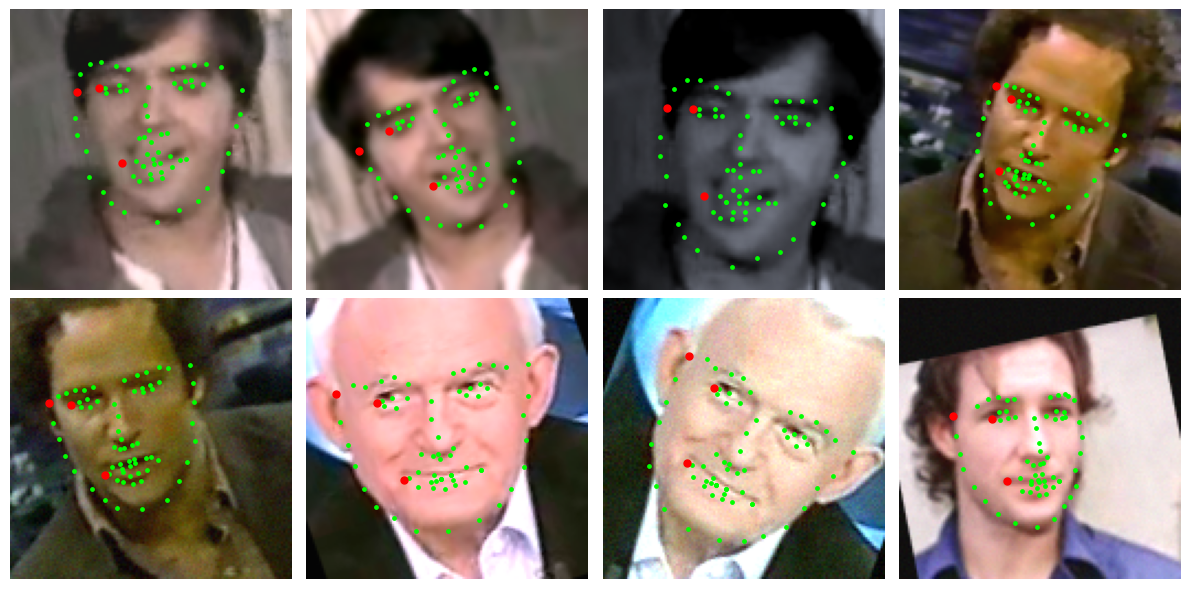

In [2]:
# ===== Cell 3: dataset (built on the provided class) + augmentation =====

# ---- the PROVIDED dataset class (dataset.py), unchanged ----
class FacialKeypointsDataset(Dataset):
    """Face Landmarks dataset."""
    def __init__(self, csv_file, root_dir, transform=None):
        self.key_pts_frame = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
    def __len__(self):
        return len(self.key_pts_frame)
    def __getitem__(self, idx):
        image_name = os.path.join(self.root_dir, self.key_pts_frame.iloc[idx, 0])
        image = mpimg.imread(image_name)
        if image.shape[2] == 4:
            image = image[:, :, 0:3]
        key_pts = self.key_pts_frame.iloc[idx, 1:].to_numpy()
        key_pts = key_pts.astype("float").reshape(-1, 2)
        sample = {"image": image, "keypoints": key_pts}
        if self.transform:
            sample = self.transform(sample)
        return sample

# ---- constants ----
INPUT = 128           # network input size
CROP_SCALE = 1.5      # crop side = 1.5 x detector box width
CY_SHIFT = 0.10       # crop centre shifted down by 0.1 x box width
KP_EXTENT_RATIO, KP_CY_OFFSET = 0.885, 0.162   # measured: landmark extent / box width, centre offset

# 68-point left/right permutation for horizontal flip
FLIP_IDX = np.array(
    list(range(16, -1, -1)) +                                   # jaw
    list(range(26, 21, -1)) + list(range(21, 16, -1)) +         # brows
    [27, 28, 29, 30] + [35, 34, 33, 32, 31] +                   # nose
    [45, 44, 43, 42, 47, 46, 39, 38, 37, 36, 41, 40] +          # eyes
    [54, 53, 52, 51, 50, 49, 48, 59, 58, 57, 56, 55] +          # outer mouth
    [64, 63, 62, 61, 60, 67, 66, 65])                           # inner mouth
assert sorted(FLIP_IDX.tolist()) == list(range(68))

REGIONS = {'jaw': range(0, 17), 'brows': range(17, 27), 'nose': range(27, 36),
           'eyes': range(36, 48), 'mouth': range(48, 68)}
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

def identity_of(name):
    return re.sub(r'_\d+\.jpg$', '', name)

def box_from_keypoints(kp):
    """Detector-like box built from GT landmarks (training fallback / oracle evaluation)."""
    lo, hi = kp.min(0), kp.max(0)
    w = (hi - lo).max() / KP_EXTENT_RATIO
    cx, cy = (lo[0] + hi[0]) / 2, (lo[1] + hi[1]) / 2 - KP_CY_OFFSET * w
    return [cx - w / 2, cy - w / 2, w, w]

def fallback_box(h, w):
    """Used when the detector finds no face (no GT used)."""
    s = 0.55 * min(h, w)
    return [w / 2 - s / 2, h / 2 - s / 2 - 0.05 * h, s, s]

def box_ok(box, kp):
    cx, cy, w = box[0] + box[2] / 2, box[1] + box[3] / 2, box[2]
    lo, hi = kp.min(0), kp.max(0)
    rx, ry = ((lo[0] + hi[0]) / 2 - cx) / w, ((lo[1] + hi[1]) / 2 - cy) / w
    rs = (hi - lo).max() / w
    return abs(rx) < 0.3 and abs(ry - KP_CY_OFFSET) < 0.3 and 0.6 < rs < 1.6

def crop_matrix(box, scale=1.0, rot_deg=0.0, shift=(0.0, 0.0), flip=False):
    """2x3 affine: original image coords -> INPUT x INPUT crop coords."""
    x, y, w, h = box
    side = CROP_SCALE * w * scale
    cx = x + w / 2 + shift[0] * w
    cy = y + h / 2 + CY_SHIFT * w + shift[1] * w
    s = INPUT / side
    a = np.deg2rad(rot_deg)
    R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]]) * s
    if flip:
        R = np.array([[-1, 0], [0, 1]]) @ R
    t = np.array([INPUT / 2, INPUT / 2]) - R @ np.array([cx, cy])
    return np.hstack([R, t[:, None]]).astype(np.float32)

def apply_affine(M, pts):
    return pts @ M[:, :2].T + M[:, 2]

def to_tensor(crop_rgb):
    x = (crop_rgb.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())

def kp_to_target(kp):  return (kp - INPUT / 2) / (INPUT / 2)   # pixels -> [-1, 1]
def target_to_kp(t):   return t * (INPUT / 2) + INPUT / 2

def photometric(img):
    rng = np.random
    x = img.astype(np.float32)
    if rng.rand() < 0.2:  x = np.repeat(x.mean(2, keepdims=True), 3, 2)        # grayscale
    x = x * rng.uniform(0.7, 1.3) + rng.uniform(-25, 25)                       # contrast/brightness
    x = x * rng.uniform(0.9, 1.1, (1, 1, 3))                                   # colour cast
    if rng.rand() < 0.25:
        k = int(rng.choice([3, 5])); x = cv2.GaussianBlur(x, (k, k), 0)        # blur
    if rng.rand() < 0.3:  x = x + rng.normal(0, rng.uniform(2, 8), x.shape)    # noise
    return x.clip(0, 255).astype(np.uint8)


class KeypointCropDataset(FacialKeypointsDataset):
    """mode='train' -> random augmentation, 'eval' -> deterministic crop.
    box_source='detector' (realistic) or 'gt' (oracle box from GT landmarks)."""
    def __init__(self, csv_file, split, mode='eval', box_source='detector', indices=None):
        super().__init__(csv_file, f'{DATA}/{split}')
        if indices is not None:
            self.key_pts_frame = self.key_pts_frame.iloc[indices].reset_index(drop=True)
        self.mode, self.box_source = mode, box_source
        self.names = list(self.key_pts_frame.iloc[:, 0])
        self.det_boxes = [BOXES.get(f'{split}/{n}') for n in self.names]
        self._cache = {}

    def raw(self, idx):
        if idx not in self._cache:
            s = FacialKeypointsDataset.__getitem__(self, idx)
            img = s['image']
            if img.dtype != np.uint8:
                img = (img * 255).clip(0, 255).astype(np.uint8)
            self._cache[idx] = (np.ascontiguousarray(img), s['keypoints'].astype(np.float32))
        return self._cache[idx]

    def box_for(self, idx, img, kp):
        det = self.det_boxes[idx]
        if self.box_source == 'gt':
            return box_from_keypoints(kp)
        if self.mode == 'train':
            return det if (det is not None and box_ok(det, kp)) else box_from_keypoints(kp)
        return det if det is not None else fallback_box(*img.shape[:2])

    def __getitem__(self, idx):
        img, kp = self.raw(idx)
        box = self.box_for(idx, img, kp)
        if self.mode == 'train':
            rng = np.random
            M = crop_matrix(box, scale=rng.uniform(0.9, 1.15), rot_deg=rng.uniform(-20, 20),
                            shift=rng.normal(0, 0.06, 2).clip(-0.15, 0.15), flip=rng.rand() < 0.5)
        else:
            M = crop_matrix(box)
        crop = cv2.warpAffine(img, M, (INPUT, INPUT), flags=cv2.INTER_LINEAR)
        kp_c = apply_affine(M, kp)
        if self.mode == 'train':
            if M[0, 0] * M[1, 1] - M[0, 1] * M[1, 0] < 0:   # mirrored -> swap left/right labels
                kp_c = kp_c[FLIP_IDX]
            crop = photometric(crop)
        return {'image': to_tensor(crop),
                'keypoints': torch.from_numpy(kp_to_target(kp_c).astype(np.float32)),
                'M': torch.from_numpy(M), 'idx': idx}


# ---- visual check: 8 augmented samples (red = left-side points 0, 36, 48) ----
ds_vis = KeypointCropDataset(TRAIN_CSV, 'training', mode='train')
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
np.random.seed(0)
for ax, i in zip(axes.ravel(), [0, 0, 0, 5, 5, 100, 100, 2000]):
    s = ds_vis[i]
    im = ((s['image'].numpy().transpose(1, 2, 0) * STD + MEAN)).clip(0, 1)
    kp = target_to_kp(s['keypoints'].numpy())
    ax.imshow(im); ax.scatter(kp[:, 0], kp[:, 1], s=6, c='lime')
    ax.scatter(kp[[0, 36, 48], 0], kp[[0, 36, 48], 1], s=25, c='red'); ax.axis('off')
plt.tight_layout(); plt.show()

In [3]:
# ===== Cell 4: model, loss, metrics =====
class KeypointNet(nn.Module):
    """ResNet-18 trunk + spatial head (keeps the 4x4 map instead of global pooling)."""
    def __init__(self, n_points=68, pretrained=True, input_size=INPUT):
        super().__init__()
        r = torchvision.models.resnet18(weights='IMAGENET1K_V1' if pretrained else None)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool)
        self.body = nn.Sequential(r.layer1, r.layer2, r.layer3, r.layer4)
        fs = input_size // 32
        self.head = nn.Sequential(
            nn.Conv2d(512, 128, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Flatten(), nn.Dropout(0.2), nn.Linear(128 * fs * fs, 512), nn.ReLU(inplace=True),
            nn.Linear(512, n_points * 2))
        self.n = n_points
    def forward(self, x):
        return self.head(self.body(self.stem(x))).view(-1, self.n, 2)


class WingLoss(nn.Module):
    """Wing loss (Feng et al., CVPR 2018), in crop-pixel units, with optional per-point weights."""
    def __init__(self, w=10.0, eps=2.0, scale=64.0):
        super().__init__()
        self.w, self.eps, self.scale = w, eps, scale
        self.C = w - w * np.log(1 + w / eps)
    def forward(self, pred, target, point_w=None):
        d = (pred - target).abs() * self.scale
        loss = torch.where(d < self.w, self.w * torch.log(1 + d / self.eps), d - self.C)
        if point_w is not None:
            loss = loss * point_w
        return loss.mean()


# ---- metrics (from scratch) ----
def interocular(gt):        return np.linalg.norm(gt[:, 36] - gt[:, 45], axis=-1)
def point_errors(pred, gt): return np.linalg.norm(pred - gt, axis=-1)
def nme_interocular(pred, gt): return point_errors(pred, gt).mean(1) / interocular(gt)
def rmse(pred, gt):         return np.sqrt((point_errors(pred, gt) ** 2).mean(1))
def ced_auc(nme, thr=0.08, steps=1000):
    xs = np.linspace(0, thr, steps)
    ys = np.array([(nme <= x).mean() for x in xs])
    auc = np.sum((ys[1:] + ys[:-1]) / 2 * np.diff(xs)) / thr      # trapezoid rule
    return xs, ys, auc
def failure_rate(nme, thr=0.08): return float((nme > thr).mean())
def pck(pred, gt, alpha=0.1):
    d = point_errors(pred, gt) / interocular(gt)[:, None]
    return float((d <= alpha).mean())

# quick sanity check
m = KeypointNet().to(DEVICE)
print('params: %.2f M' % (sum(p.numel() for p in m.parameters()) / 1e6))
print('output shape:', m(torch.randn(2, 3, INPUT, INPUT).to(DEVICE)).shape)
del m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 32.4MB/s]


params: 12.36 M
output shape: torch.Size([2, 68, 2])


In [4]:
# ===== Cell 5: training =====
# If you already have best.pt from before: upload it into /content/outputs/ and set TRAIN = False
TRAIN = True
SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
EPOCHS = 60 if DEVICE == 'cuda' else 20      # CPU: ~4 min/epoch -> ~1.5 h
BS, LR, MOUTH_W = 32, 1e-3, 2.0
if DEVICE == 'cpu':
    torch.set_num_threads(os.cpu_count())

# ---- split by identity (no person in both train and val) ----
all_names = list(pd.read_csv(TRAIN_CSV).iloc[:, 0])
ids = sorted({identity_of(n) for n in all_names})
rng = np.random.RandomState(SEED); rng.shuffle(ids)
val_ids = set(ids[:len(ids) // 10])
tr_idx = [i for i, n in enumerate(all_names) if identity_of(n) not in val_ids]
va_idx = [i for i, n in enumerate(all_names) if identity_of(n) in val_ids]
print(f'train {len(tr_idx)} imgs | val {len(va_idx)} imgs ({len(val_ids)} identities held out)')

tr_ds = KeypointCropDataset(TRAIN_CSV, 'training', mode='train', indices=tr_idx)
va_ds = KeypointCropDataset(TRAIN_CSV, 'training', mode='eval', indices=va_idx)
NW = 2 if DEVICE == 'cuda' else 0
tl = DataLoader(tr_ds, BS, shuffle=True, num_workers=NW, drop_last=True)
vl = DataLoader(va_ds, 64, shuffle=False, num_workers=0)

model = KeypointNet(pretrained=True).to(DEVICE)
CKPT = f'{OUT}/best.pt'

if TRAIN:
    crit = WingLoss()
    w_pts = torch.ones(68, 1); w_pts[48:] = MOUTH_W; w_pts = (w_pts / w_pts.mean()).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, LR, total_steps=EPOCHS * len(tl), pct_start=0.05)
    best, LOG = 1e9, []
    for ep in range(EPOCHS):
        model.train(); t0 = time.time(); tot = 0
        for b in tl:
            x, y = b['image'].to(DEVICE), b['keypoints'].to(DEVICE)
            loss = crit(model(x), y, w_pts)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tot += loss.item()
        model.eval(); errs = []
        with torch.no_grad():
            for b in vl:
                pr = model(b['image'].to(DEVICE)).cpu().numpy()
                errs.append(nme_interocular(pr, b['keypoints'].numpy()))
        v = float(np.concatenate(errs).mean())
        LOG.append({'epoch': ep + 1, 'train_loss': tot / len(tl), 'val_nme': v})
        flag = ''
        if v < best:
            best = v; flag = '  <- best (saved)'
            torch.save({'state_dict': model.state_dict(), 'epoch': ep + 1, 'val_nme': v,
                        'val_ids': sorted(val_ids)}, CKPT)
        print(f'ep {ep+1:3d}/{EPOCHS}  loss {tot/len(tl):.3f}  val NME {100*v:.2f}%  ({time.time()-t0:.0f}s){flag}')
    json.dump(LOG, open(f'{OUT}/train_log.json', 'w'))
    print(f'best val NME: {100*best:.2f}%')
    from google.colab import files
    files.download(CKPT)                       # saves best.pt to your computer as a backup
else:
    print('TRAIN=False -> using existing', CKPT,
          '| val NME %.2f%%' % (100 * torch.load(CKPT, map_location='cpu')['val_nme']))

train 3129 imgs | val 333 imgs (34 identities held out)
ep   1/20  loss 14.534  val NME 18.74%  (308s)  <- best (saved)
ep   2/20  loss 9.463  val NME 13.94%  (282s)  <- best (saved)
ep   3/20  loss 8.447  val NME 12.20%  (287s)  <- best (saved)
ep   4/20  loss 7.996  val NME 12.69%  (284s)
ep   5/20  loss 7.844  val NME 11.51%  (282s)  <- best (saved)
ep   6/20  loss 7.623  val NME 10.36%  (282s)  <- best (saved)
ep   7/20  loss 7.139  val NME 9.49%  (288s)  <- best (saved)
ep   8/20  loss 7.002  val NME 11.46%  (286s)
ep   9/20  loss 6.909  val NME 9.80%  (283s)
ep  10/20  loss 6.687  val NME 9.31%  (285s)  <- best (saved)
ep  11/20  loss 6.509  val NME 8.78%  (280s)  <- best (saved)
ep  12/20  loss 6.171  val NME 8.42%  (295s)  <- best (saved)
ep  13/20  loss 5.969  val NME 8.85%  (285s)
ep  14/20  loss 5.795  val NME 7.92%  (277s)  <- best (saved)
ep  15/20  loss 5.638  val NME 7.98%  (280s)
ep  16/20  loss 5.470  val NME 8.05%  (289s)
ep  17/20  loss 5.383  val NME 7.73%  (282s)  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# ===== Cell 6: test-set evaluation (Task 1.2) =====
ck = torch.load(CKPT, map_location=DEVICE)
model.load_state_dict(ck['state_dict']); model.eval()
print(f"loaded best.pt (epoch {ck['epoch']}, val NME {100*ck['val_nme']:.2f}%)")

def predict(ds, tta=False):
    """Predict, then map key points back to ORIGINAL image pixels."""
    preds, gts = [], []
    flip = torch.as_tensor(FLIP_IDX)
    with torch.no_grad():
        for b in DataLoader(ds, 64):
            x = b['image'].to(DEVICE)
            out = model(x)
            if tta:                                   # average with horizontally flipped input
                f = model(torch.flip(x, dims=[3]))[:, flip].clone()
                f[..., 0] = -f[..., 0]
                out = (out + f) / 2
            kp_c = target_to_kp(out.cpu().numpy())
            for k, M, i in zip(kp_c, b['M'].numpy(), b['idx'].numpy()):
                Mi = cv2.invertAffineTransform(M)
                preds.append(k @ Mi[:, :2].T + Mi[:, 2])
                gts.append(ds.raw(int(i))[1])
    return np.array(preds), np.array(gts)

def summarise(pred, gt):
    nme = nme_interocular(pred, gt)
    xs, ys, auc = ced_auc(nme, 0.08)
    pe = point_errors(pred, gt) / interocular(gt)[:, None]
    row = {'NME %': 100 * nme.mean(), 'NME median %': 100 * np.median(nme),
           'RMSE px': rmse(pred, gt).mean(), 'AUC@0.08': auc,
           'FR@0.08 %': 100 * failure_rate(nme, 0.08), 'FR@0.10 %': 100 * failure_rate(nme, 0.10),
           'PCK@0.1 %': 100 * pck(pred, gt, 0.1)}
    for r, ix in REGIONS.items():
        row[f'{r} %'] = 100 * pe[:, list(ix)].mean()
    return row, nme, (xs, ys), pe.mean(0)

RESULTS, CURVES = {}, {}
test_det = KeypointCropDataset(TEST_CSV, 'test', mode='eval', box_source='detector')
test_gt = KeypointCropDataset(TEST_CSV, 'test', mode='eval', box_source='gt')

PRED, GT = predict(test_det)                       # main result (used later for emotion)
NAMES = np.array(test_det.names)
RESULTS['Ours - detector box'], NME_TEST, CURVES['Ours - detector box'], PER_POINT = summarise(PRED, GT)
p, g = predict(test_gt);            RESULTS['Ours - oracle box'], _, CURVES['Ours - oracle box'], _ = summarise(p, g)
p, g = predict(test_det, tta=True); RESULTS['Ours + flip TTA - detector box'], _, _, _ = summarise(p, g)
p, g = predict(test_gt, tta=True);  RESULTS['Ours + flip TTA - oracle box'], _, _, _ = summarise(p, g)

# baseline: mean training shape placed in the detector crop (no learning)
tr_eval = KeypointCropDataset(TRAIN_CSV, 'training', mode='eval')
mean_shape = np.mean([tr_eval[i]['keypoints'].numpy() for i in range(len(tr_eval))], 0)
bp = []
for i in range(len(test_det)):
    Mi = cv2.invertAffineTransform(test_det[i]['M'].numpy())
    bp.append(target_to_kp(mean_shape) @ Mi[:, :2].T + Mi[:, 2])
RESULTS['Mean-shape baseline'], _, CURVES['Mean-shape baseline'], _ = summarise(np.array(bp), GT)

table = pd.DataFrame(RESULTS).T.round(3)
pd.set_option('display.width', 250)
print(table.to_string())
table.to_csv(f'{OUT}/test_results.csv')
np.savez(f'{OUT}/pred_test.npz', pred=PRED, gt=GT, names=NAMES, nme=NME_TEST)

loaded best.pt (epoch 19, val NME 7.34%)
                                 NME %  NME median %  RMSE px  AUC@0.08  FR@0.08 %  FR@0.10 %  PCK@0.1 %   jaw %  brows %  nose %  eyes %  mouth %
Ours - detector box              6.240         5.113    3.147     0.339      7.403      3.117     89.843   7.903    6.533   5.190   5.489    5.601
Ours - oracle box                5.411         5.116    2.841     0.339      6.883      2.078     90.966   7.170    5.690   4.244   4.673    4.743
Ours + flip TTA - detector box   5.884         4.704    2.990     0.380      5.974      2.987     91.226   7.570    6.173   4.821   5.081    5.266
Ours + flip TTA - oracle box     4.999         4.733    2.647     0.385      3.766      1.299     92.712   6.735    5.298   3.839   4.217    4.367
Mean-shape baseline             15.729        12.702    7.993     0.019     88.831     72.857     42.011  21.640   14.309  14.037  10.888   15.081


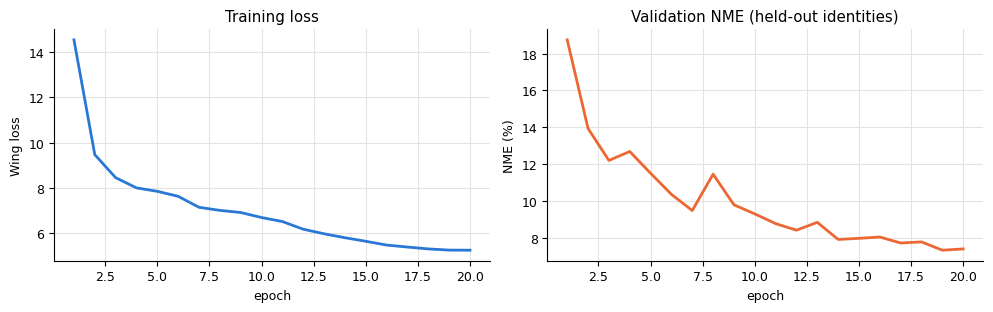

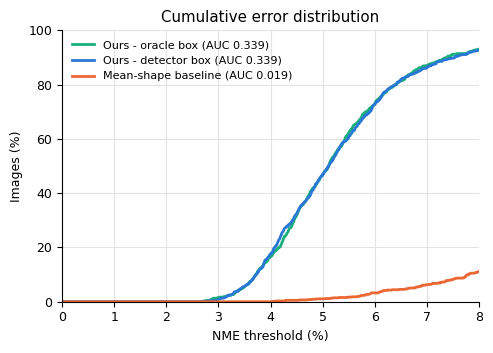

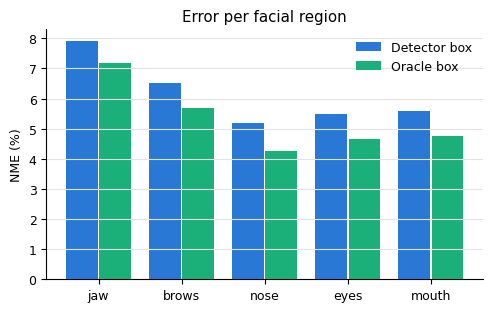

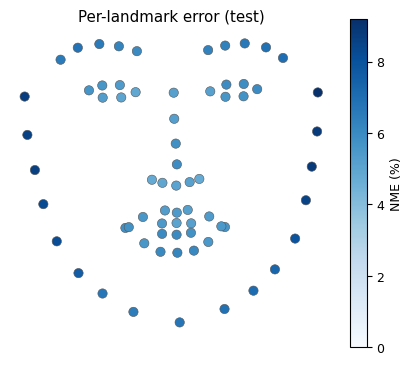

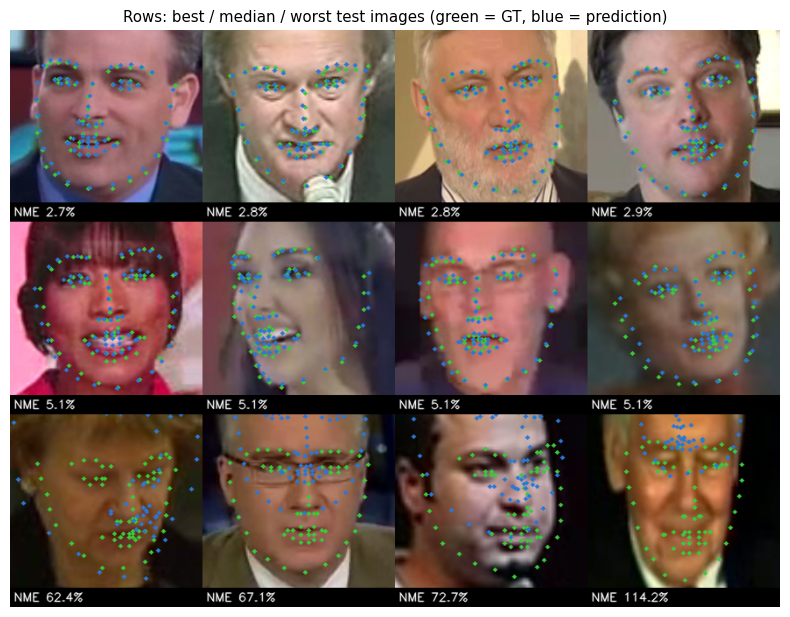

In [6]:
# ===== Cell 7: figures (training curves, CED, per-region, per-landmark, qualitative) =====
FIG = f'{OUT}/figures'; os.makedirs(FIG, exist_ok=True)
COL = {'blue': '#2a78d6', 'orange': '#eb6834', 'aqua': '#1baf7a'}
plt.rcParams.update({'font.size': 9, 'axes.grid': True, 'grid.color': '#e3e3e3',
                     'axes.spines.top': False, 'axes.spines.right': False})

# 1) training curves
log = json.load(open(f'{OUT}/train_log.json')) if os.path.exists(f'{OUT}/train_log.json') else LOG
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ep = [l['epoch'] for l in log]
ax[0].plot(ep, [l['train_loss'] for l in log], color=COL['blue'], lw=2); ax[0].set(xlabel='epoch', ylabel='Wing loss', title='Training loss')
ax[1].plot(ep, [100 * l['val_nme'] for l in log], color=COL['orange'], lw=2); ax[1].set(xlabel='epoch', ylabel='NME (%)', title='Validation NME (held-out identities)')
plt.tight_layout(); plt.savefig(f'{FIG}/training_curves.png', dpi=200); plt.show()

# 2) CED curve
fig, ax = plt.subplots(figsize=(5, 3.6))
for k, c in [('Ours - oracle box', COL['aqua']), ('Ours - detector box', COL['blue']), ('Mean-shape baseline', COL['orange'])]:
    xs, ys = CURVES[k]
    ax.plot(xs * 100, ys * 100, color=c, lw=2, label=f"{k} (AUC {RESULTS[k]['AUC@0.08']:.3f})")
ax.set(xlabel='NME threshold (%)', ylabel='Images (%)', title='Cumulative error distribution', xlim=(0, 8), ylim=(0, 100))
ax.legend(fontsize=8, loc='upper left', frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/ced.png', dpi=200); plt.show()

# 3) per-region error
regs = list(REGIONS); x = np.arange(len(regs))
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(x - 0.2, [RESULTS['Ours - detector box'][f'{r} %'] for r in regs], 0.38, color=COL['blue'], label='Detector box')
ax.bar(x + 0.2, [RESULTS['Ours - oracle box'][f'{r} %'] for r in regs], 0.38, color=COL['aqua'], label='Oracle box')
ax.set_xticks(x, regs); ax.set(ylabel='NME (%)', title='Error per facial region'); ax.grid(axis='x', visible=False)
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/per_region.png', dpi=200); plt.show()

# 4) per-landmark error on the mean face
a = GT - GT[:, 27:28]; iod = interocular(GT)
mean_face = (a / iod[:, None, None]).mean(0)
fig, ax = plt.subplots(figsize=(4.2, 4))
sc = ax.scatter(mean_face[:, 0], -mean_face[:, 1], c=100 * PER_POINT, cmap='Blues', s=45, edgecolor='#555', lw=0.4, vmin=0)
plt.colorbar(sc, ax=ax, fraction=0.046, label='NME (%)'); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Per-landmark error (test)')
plt.tight_layout(); plt.savefig(f'{FIG}/per_landmark.png', dpi=200); plt.show()

# 5) qualitative: 4 best / 4 median / 4 worst  (green = ground truth, blue = prediction)
def draw(name, pred, gtk=None, size=220, label=None, split='test'):
    img = cv2.cvtColor(cv2.imread(f'{DATA}/{split}/{name}'), cv2.COLOR_BGR2RGB)
    ref = gtk if gtk is not None else pred
    lo, hi = ref.min(0), ref.max(0); c = (lo + hi) / 2; s = 1.4 * (hi - lo).max(); k = size / s
    Mx = np.array([[k, 0, size / 2 - k * c[0]], [0, k, size / 2 - k * c[1]]])
    t = cv2.warpAffine(img, Mx, (size, size))
    for pts, color in [(gtk, (60, 200, 60)), (pred, (42, 120, 214))]:
        if pts is None: continue
        for px, py in pts @ Mx[:, :2].T + Mx[:, 2]:
            cv2.circle(t, (int(round(px)), int(round(py))), 2, color, -1, cv2.LINE_AA)
    if label:
        cv2.rectangle(t, (0, size - 22), (size, size), (0, 0, 0), -1)
        cv2.putText(t, label, (4, size - 7), 0, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
    return t

order = np.argsort(NME_TEST); n = len(order)
picks = list(order[:4]) + list(order[n // 2 - 2: n // 2 + 2]) + list(order[-4:])
tiles = [draw(NAMES[i], PRED[i], GT[i], label=f'NME {100 * NME_TEST[i]:.1f}%') for i in picks]
grid = np.vstack([np.hstack(tiles[r * 4:(r + 1) * 4]) for r in range(3)])
cv2.imwrite(f'{FIG}/qualitative_best_median_worst.jpg', cv2.cvtColor(grid, cv2.COLOR_RGB2BGR))
plt.figure(figsize=(10, 7.5)); plt.imshow(grid); plt.axis('off')
plt.title('Rows: best / median / worst test images (green = GT, blue = prediction)'); plt.show()

thresholds (tuned on 120 labelled TRAIN faces, GT key points): T_pos=0.25  T_neg=-2.00  T_frown=0.80   train macro-F1=0.505

labelled TEST faces (150) - rule on GT key points:  acc 0.633  macro-F1 0.469  per-class F1 {'negative': 0.067, 'neutral': 0.733, 'positive': 0.608}
                rule negative  rule neutral  rule positive
label negative              1             4              1
label neutral              20            70             23
label positive              3             4             24

labelled TEST faces (150) - rule on PREDICTED key points:  acc 0.527  macro-F1 0.291  per-class F1 {'negative': 0.0, 'neutral': 0.676, 'positive': 0.198}
                rule negative  rule neutral  rule positive
label negative              0             3              3
label neutral               3            71             39
label positive              0            23              8

all 770 test faces - GT-based vs prediction-based emotion: agreement 0.596  Cohen kappa 0.222  val

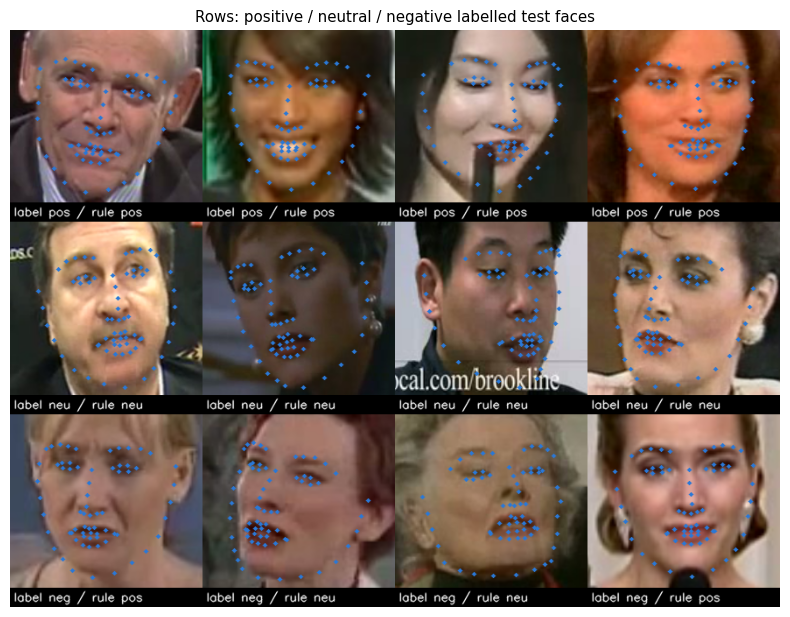

In [7]:
# ===== Cell 8: rule-based emotion: positive / neutral / negative (Task 1.3) =====
CLS = ['negative', 'neutral', 'positive']

def align(kp):
    kp = np.asarray(kp, float)
    d = kp[42:48].mean(0) - kp[36:42].mean(0)
    a = np.arctan2(d[1], d[0]); c, s = np.cos(-a), np.sin(-a)
    return (kp - kp[27]) @ np.array([[c, -s], [s, c]]).T / np.linalg.norm(kp[36] - kp[45])

def cues(kp):
    a = align(kp)
    return np.array([
        a[[51, 57, 62, 66], 1].mean() - a[[48, 54], 1].mean(),          # lift: corners above lip centre
        np.linalg.norm(a[54] - a[48]) / np.linalg.norm(a[16] - a[0]),   # w_face: mouth width / face width
        np.linalg.norm(a[64] - a[60]),                                  # w_inner (analysis only)
        a[36:48, 1].mean() - a[17:27, 1].mean(),                        # brow: brow-to-eye height
        np.linalg.norm(a[22] - a[21])])                                 # gap (analysis only)

def scores(C, mu, sd):
    z = (C - mu) / sd
    return (z[:, 0] + z[:, 1]) / 2, -z[:, 3]

def rule(V, F, T):
    return np.where(V >= T[0], 'positive', np.where((V <= T[1]) | (F >= T[2]), 'negative', 'neutral'))

def macro_f1(y, p):
    f = []
    for c in CLS:
        tp = np.sum((y == c) & (p == c)); fp = np.sum((y != c) & (p == c)); fn = np.sum((y == c) & (p != c))
        f.append(0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f)), dict(zip(CLS, [round(float(v), 3) for v in f]))

def confusion(y, p):
    return pd.DataFrame([[int(np.sum((y == r) & (p == c))) for c in CLS] for r in CLS],
                        index=[f'label {c}' for c in CLS], columns=[f'rule {c}' for c in CLS])

def kappa(y, p):
    po = np.mean(y == p); pe = sum(np.mean(y == c) * np.mean(p == c) for c in CLS)
    return float((po - pe) / (1 - pe))

def sample_clips(csv, n):
    names = list(pd.read_csv(csv).iloc[:, 0]); clips = {}
    for i, nm in enumerate(names):
        clips.setdefault(re.sub(r'\d\.jpg$', '', nm), []).append(i)
    rng = np.random.RandomState(1); keys = sorted(clips); rng.shuffle(keys)
    return [names[int(rng.choice(clips[k]))] for k in keys[:n]]

POS = {'training': [3,7,15,16,23,28,30,36,41,42,43,45,47,48,49,52,53,55,61,81,85,93,102,107,108,110,112,115,117],
       'test': [7,10,15,28,32,35,42,56,61,66,67,68,71,72,73,83,85,86,91,93,94,95,101,102,106,108,121,125,126,127,131]}
NEG = {'training': [2,5,11,56,82,87], 'test': [3,4,49,84,136,149]}
LABELS = {}
for split, csv, n in [('training', TRAIN_CSV, 120), ('test', TEST_CSV, 150)]:
    sel = sample_clips(csv, n)
    LABELS[split] = pd.DataFrame({'image': sel, 'label': ['positive' if i in POS[split] else 'negative' if i in NEG[split]
                                                         else 'neutral' for i in range(n)]})
tr_df = pd.read_csv(TRAIN_CSV); tr_df = tr_df.set_index(tr_df.columns[0])
te_df = pd.read_csv(TEST_CSV);  te_df = te_df.set_index(te_df.columns[0])
gt_kp = lambda df, n: df.loc[n].values.astype(float).reshape(68, 2)
C_all = np.array([cues(gt_kp(tr_df, n)) for n in tr_df.index])
MU, SD = C_all.mean(0), C_all.std(0)
Ltr = LABELS['training']; ytr = Ltr.label.values
Vtr, Ftr = scores(np.array([cues(gt_kp(tr_df, n)) for n in Ltr.image]), MU, SD)
best = (-1, None)
for T in itertools.product(np.arange(0.0, 1.51, 0.05), np.arange(-2.0, -0.49, 0.05), np.arange(0.5, 3.01, 0.1)):
    f = macro_f1(ytr, rule(Vtr, Ftr, T))[0]
    if f > best[0] + 1e-9: best = (f, T)
T = best[1]
Lte = LABELS['test']; yte = Lte.label.values
Vg, Fg = scores(np.array([cues(gt_kp(te_df, n)) for n in Lte.image]), MU, SD)
pg = rule(Vg, Fg, T)

# ---- predicted key points are z-scored with statistics of PREDICTED shapes (held-out val identities),
#      because direct regression shrinks shapes toward the mean face ----
pv, _ = predict(va_ds)
Cp = np.array([cues(k) for k in pv]); MU_P, SD_P = Cp.mean(0), Cp.std(0)

pmap = {n: i for i, n in enumerate(NAMES)}
Vp, Fp = scores(np.array([cues(PRED[pmap[n]]) for n in Lte.image]), MU_P, SD_P)
pp = rule(Vp, Fp, T)

# ---- label-free consistency on ALL 770 test faces: rule(GT key points) vs rule(predicted key points) ----
Va, Fa = scores(np.array([cues(k) for k in GT]), MU, SD)
Vb, Fb = scores(np.array([cues(k) for k in PRED]), MU_P, SD_P)
ea, eb = rule(Va, Fa, T), rule(Vb, Fb, T)

print(f'thresholds (tuned on {len(ytr)} labelled TRAIN faces, GT key points): '
      f'T_pos={T[0]:.2f}  T_neg={T[1]:.2f}  T_frown={T[2]:.2f}   train macro-F1={best[0]:.3f}')
print(f'\nlabelled TEST faces ({len(yte)}) - rule on GT key points:  acc {np.mean(pg == yte):.3f}  macro-F1 {macro_f1(yte, pg)[0]:.3f}  per-class F1 {macro_f1(yte, pg)[1]}')
print(confusion(yte, pg).to_string())
print(f'\nlabelled TEST faces ({len(yte)}) - rule on PREDICTED key points:  acc {np.mean(pp == yte):.3f}  macro-F1 {macro_f1(yte, pp)[0]:.3f}  per-class F1 {macro_f1(yte, pp)[1]}')
print(confusion(yte, pp).to_string())
print(f'\nall {len(ea)} test faces - GT-based vs prediction-based emotion: agreement {np.mean(ea == eb):.3f}  '
      f'Cohen kappa {kappa(ea, eb):.3f}  valence correlation r {np.corrcoef(Va, Vb)[0, 1]:.3f}')
print('cue fidelity corr(GT, pred) [lift, w_face, w_inner, brow, gap]:',
      np.round([np.corrcoef(np.array([cues(k) for k in GT])[:, j], np.array([cues(k) for k in PRED])[:, j])[0, 1] for j in range(5)], 2))

json.dump({'T': list(map(float, T)), 'mu': MU.tolist(), 'sd': SD.tolist(), 'mu_pred': MU_P.tolist(), 'sd_pred': SD_P.tolist()},
          open(f'{OUT}/emotion_params.json', 'w'), indent=1)
pd.concat([LABELS['training'].assign(split='training'), LABELS['test'].assign(split='test')]).to_csv(f'{OUT}/emotion_labels.csv', index=False)

# ---- examples: 4 per class (blue = predicted key points) ----
rows = []
for cls in CLS[::-1]:
    idx = np.where(yte == cls)[0]
    idx = sorted(idx, key=lambda i: pp[i] != cls)[:4]           # correct ones first
    tiles = [draw(Lte.image[i], PRED[pmap[Lte.image[i]]], label=f'label {cls[:3]} / rule {pp[i][:3]}') for i in idx]
    tiles += [np.zeros_like(tiles[0])] * (4 - len(tiles))
    rows.append(np.hstack(tiles))
grid = np.vstack(rows)
cv2.imwrite(f'{FIG}/emotion_examples.jpg', cv2.cvtColor(grid, cv2.COLOR_RGB2BGR))
plt.figure(figsize=(10, 7.5)); plt.imshow(grid); plt.axis('off'); plt.title('Rows: positive / neutral / negative labelled test faces'); plt.show()

In [8]:
# ===== Cell 9: fine-tune from best.pt with stronger mouth weighting =====
FT_EPOCHS, FT_LR, FT_MOUTH_W = 12, 5e-4, 3.0
CKPT_FT = f'{OUT}/best_ft.pt'

ck = torch.load(f'{OUT}/best.pt', map_location=DEVICE)
model.load_state_dict(ck['state_dict'])
best = ck['val_nme']
print(f'start from best.pt: val NME {100*best:.2f}%')
torch.save(ck, CKPT_FT)                       # fallback: if no epoch improves, keep the original

crit = WingLoss()
w_pts = torch.ones(68, 1); w_pts[48:] = FT_MOUTH_W; w_pts = (w_pts / w_pts.mean()).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, FT_LR, total_steps=FT_EPOCHS * len(tl), pct_start=0.1)

old_log = json.load(open(f'{OUT}/train_log.json'))
n0 = len(old_log); FT_LOG = []
for ep in range(FT_EPOCHS):
    model.train(); t0 = time.time(); tot = 0
    for b in tl:
        x, y = b['image'].to(DEVICE), b['keypoints'].to(DEVICE)
        loss = crit(model(x), y, w_pts)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        tot += loss.item()
    model.eval(); errs = []
    with torch.no_grad():
        for b in vl:
            errs.append(nme_interocular(model(b['image'].to(DEVICE)).cpu().numpy(), b['keypoints'].numpy()))
    v = float(np.concatenate(errs).mean())
    FT_LOG.append({'epoch': n0 + ep + 1, 'train_loss': tot / len(tl), 'val_nme': v})
    flag = ''
    if v < best:
        best = v; flag = '  <- best (saved)'
        torch.save({'state_dict': model.state_dict(), 'epoch': n0 + ep + 1, 'val_nme': v,
                    'val_ids': sorted(val_ids)}, CKPT_FT)
    print(f'ft {ep+1:2d}/{FT_EPOCHS}  loss {tot/len(tl):.3f}  val NME {100*v:.2f}%  ({time.time()-t0:.0f}s){flag}')

json.dump(old_log + FT_LOG, open(f'{OUT}/train_log.json', 'w'))   # full curve (stage 1 + fine-tune)
CKPT = CKPT_FT                                                   # cells 6-8 will now use the fine-tuned model
print(f'best val NME after fine-tune: {100*best:.2f}%  -> CKPT = {CKPT}')
from google.colab import files
files.download(CKPT_FT)

start from best.pt: val NME 7.34%
ft  1/12  loss 5.488  val NME 8.05%  (288s)
ft  2/12  loss 6.153  val NME 8.41%  (275s)
ft  3/12  loss 5.971  val NME 8.16%  (274s)
ft  4/12  loss 5.806  val NME 7.69%  (275s)
ft  5/12  loss 5.626  val NME 7.56%  (276s)
ft  6/12  loss 5.518  val NME 7.54%  (276s)
ft  7/12  loss 5.394  val NME 7.18%  (276s)  <- best (saved)
ft  8/12  loss 5.173  val NME 7.20%  (278s)
ft  9/12  loss 5.070  val NME 7.07%  (274s)  <- best (saved)
ft 10/12  loss 4.949  val NME 7.22%  (278s)
ft 11/12  loss 4.905  val NME 7.01%  (274s)  <- best (saved)
ft 12/12  loss 4.854  val NME 6.88%  (273s)  <- best (saved)
best val NME after fine-tune: 6.88%  -> CKPT = /content/outputs/best_ft.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# ===== Cell 6: test-set evaluation (Task 1.2) =====
CKPT = f'{OUT}/best_ft.pt' if os.path.exists(f'{OUT}/best_ft.pt') else f'{OUT}/best.pt'
ck = torch.load(CKPT, map_location=DEVICE)
model.load_state_dict(ck['state_dict']); model.eval()
print(f"loaded {CKPT} (epoch {ck['epoch']}, val NME {100*ck['val_nme']:.2f}%)")

def predict(ds, tta=False):
    """Predict, then map key points back to ORIGINAL image pixels."""
    preds, gts = [], []
    flip = torch.as_tensor(FLIP_IDX)
    with torch.no_grad():
        for b in DataLoader(ds, 64):
            x = b['image'].to(DEVICE)
            out = model(x)
            if tta:                                   # average with horizontally flipped input
                f = model(torch.flip(x, dims=[3]))[:, flip].clone()
                f[..., 0] = -f[..., 0]
                out = (out + f) / 2
            kp_c = target_to_kp(out.cpu().numpy())
            for k, M, i in zip(kp_c, b['M'].numpy(), b['idx'].numpy()):
                Mi = cv2.invertAffineTransform(M)
                preds.append(k @ Mi[:, :2].T + Mi[:, 2])
                gts.append(ds.raw(int(i))[1])
    return np.array(preds), np.array(gts)

def summarise(pred, gt):
    nme = nme_interocular(pred, gt)
    xs, ys, auc = ced_auc(nme, 0.08)
    pe = point_errors(pred, gt) / interocular(gt)[:, None]
    row = {'NME %': 100 * nme.mean(), 'NME median %': 100 * np.median(nme),
           'RMSE px': rmse(pred, gt).mean(), 'AUC@0.08': auc,
           'FR@0.08 %': 100 * failure_rate(nme, 0.08), 'FR@0.10 %': 100 * failure_rate(nme, 0.10),
           'PCK@0.1 %': 100 * pck(pred, gt, 0.1)}
    for r, ix in REGIONS.items():
        row[f'{r} %'] = 100 * pe[:, list(ix)].mean()
    return row, nme, (xs, ys), pe.mean(0)

RESULTS, CURVES = {}, {}
test_det = KeypointCropDataset(TEST_CSV, 'test', mode='eval', box_source='detector')
test_gt = KeypointCropDataset(TEST_CSV, 'test', mode='eval', box_source='gt')

PRED, GT = predict(test_det)                       # main result (used later for emotion)
NAMES = np.array(test_det.names)
RESULTS['Ours - detector box'], NME_TEST, CURVES['Ours - detector box'], PER_POINT = summarise(PRED, GT)
p, g = predict(test_gt);            RESULTS['Ours - oracle box'], _, CURVES['Ours - oracle box'], _ = summarise(p, g)
p, g = predict(test_det, tta=True); RESULTS['Ours + flip TTA - detector box'], _, _, _ = summarise(p, g)
p, g = predict(test_gt, tta=True);  RESULTS['Ours + flip TTA - oracle box'], _, _, _ = summarise(p, g)

# baseline: mean training shape placed in the detector crop (no learning)
tr_eval = KeypointCropDataset(TRAIN_CSV, 'training', mode='eval')
mean_shape = np.mean([tr_eval[i]['keypoints'].numpy() for i in range(len(tr_eval))], 0)
bp = []
for i in range(len(test_det)):
    Mi = cv2.invertAffineTransform(test_det[i]['M'].numpy())
    bp.append(target_to_kp(mean_shape) @ Mi[:, :2].T + Mi[:, 2])
RESULTS['Mean-shape baseline'], _, CURVES['Mean-shape baseline'], _ = summarise(np.array(bp), GT)

table = pd.DataFrame(RESULTS).T.round(3)
pd.set_option('display.width', 250)
print(table.to_string())
table.to_csv(f'{OUT}/test_results.csv')
np.savez(f'{OUT}/pred_test.npz', pred=PRED, gt=GT, names=NAMES, nme=NME_TEST)

loaded /content/outputs/best_ft.pt (epoch 32, val NME 6.88%)
                                 NME %  NME median %  RMSE px  AUC@0.08  FR@0.08 %  FR@0.10 %  PCK@0.1 %   jaw %  brows %  nose %  eyes %  mouth %
Ours - detector box              5.821         4.762    2.922     0.376      4.935      2.987     91.593   7.269    6.060   4.947   5.012    5.349
Ours - oracle box                5.087         4.796    2.651     0.374      3.766      1.039     92.756   6.599    5.285   4.112   4.294    4.617
Ours + flip TTA - detector box   5.504         4.410    2.786     0.414      4.286      2.468     92.844   6.939    5.840   4.534   4.798    4.976
Ours + flip TTA - oracle box     4.720         4.489    2.476     0.418      2.597      0.779     94.301   6.176    5.027   3.680   4.037    4.208
Mean-shape baseline             15.729        12.702    7.993     0.019     88.831     72.857     42.011  21.640   14.309  14.037  10.888   15.081


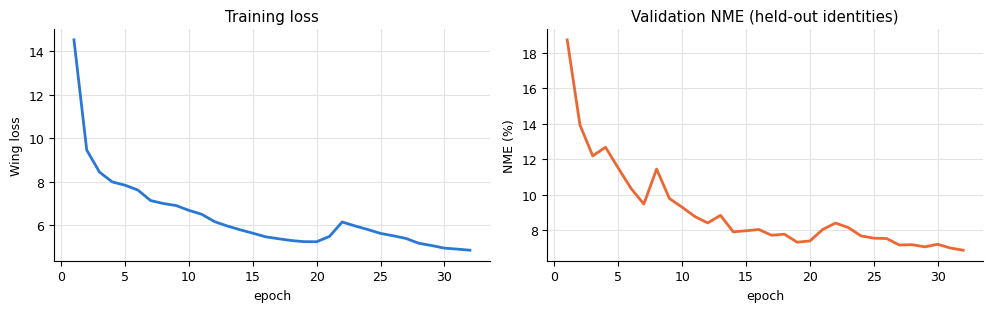

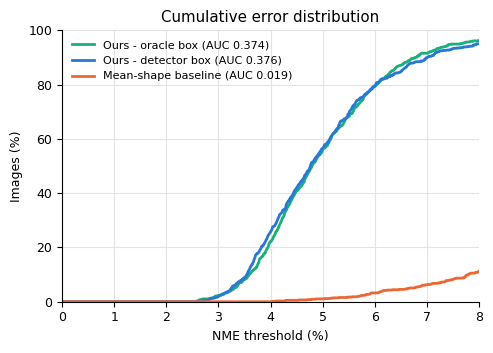

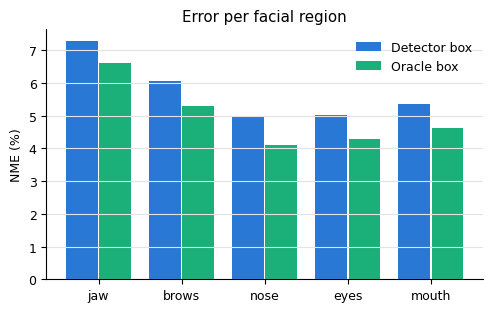

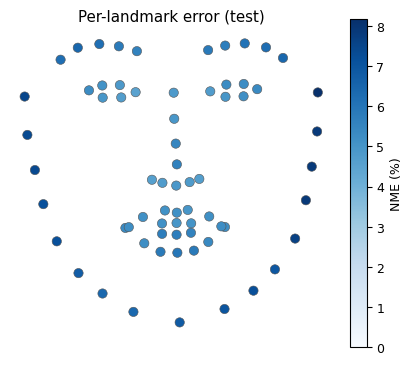

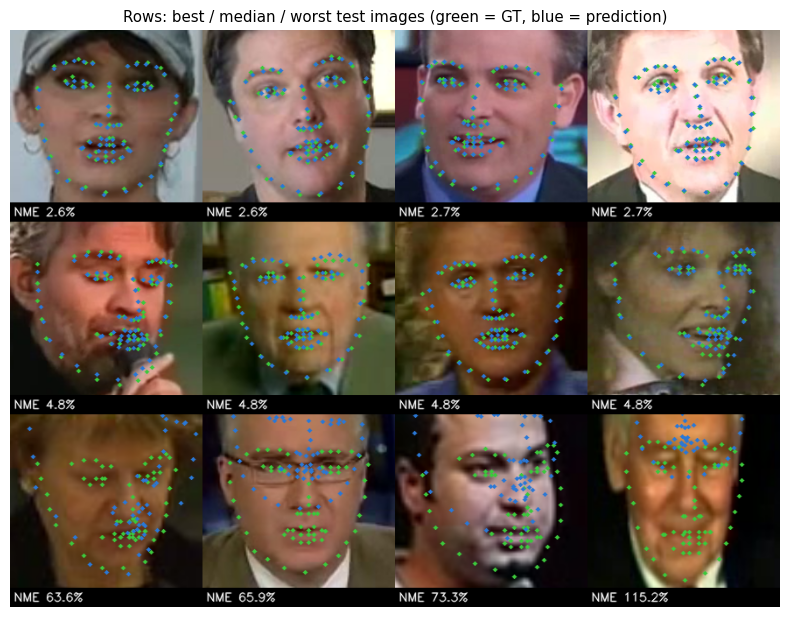

In [10]:
# ===== Cell 7: figures (training curves, CED, per-region, per-landmark, qualitative) =====
FIG = f'{OUT}/figures'; os.makedirs(FIG, exist_ok=True)
COL = {'blue': '#2a78d6', 'orange': '#eb6834', 'aqua': '#1baf7a'}
plt.rcParams.update({'font.size': 9, 'axes.grid': True, 'grid.color': '#e3e3e3',
                     'axes.spines.top': False, 'axes.spines.right': False})

# 1) training curves (stage 1 + fine-tune)
log = json.load(open(f'{OUT}/train_log.json'))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ep = [l['epoch'] for l in log]
ax[0].plot(ep, [l['train_loss'] for l in log], color=COL['blue'], lw=2); ax[0].set(xlabel='epoch', ylabel='Wing loss', title='Training loss')
ax[1].plot(ep, [100 * l['val_nme'] for l in log], color=COL['orange'], lw=2); ax[1].set(xlabel='epoch', ylabel='NME (%)', title='Validation NME (held-out identities)')
plt.tight_layout(); plt.savefig(f'{FIG}/training_curves.png', dpi=200); plt.show()

# 2) CED curve
fig, ax = plt.subplots(figsize=(5, 3.6))
for k, c in [('Ours - oracle box', COL['aqua']), ('Ours - detector box', COL['blue']), ('Mean-shape baseline', COL['orange'])]:
    xs, ys = CURVES[k]
    ax.plot(xs * 100, ys * 100, color=c, lw=2, label=f"{k} (AUC {RESULTS[k]['AUC@0.08']:.3f})")
ax.set(xlabel='NME threshold (%)', ylabel='Images (%)', title='Cumulative error distribution', xlim=(0, 8), ylim=(0, 100))
ax.legend(fontsize=8, loc='upper left', frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/ced.png', dpi=200); plt.show()

# 3) per-region error
regs = list(REGIONS); x = np.arange(len(regs))
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(x - 0.2, [RESULTS['Ours - detector box'][f'{r} %'] for r in regs], 0.38, color=COL['blue'], label='Detector box')
ax.bar(x + 0.2, [RESULTS['Ours - oracle box'][f'{r} %'] for r in regs], 0.38, color=COL['aqua'], label='Oracle box')
ax.set_xticks(x, regs); ax.set(ylabel='NME (%)', title='Error per facial region'); ax.grid(axis='x', visible=False)
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/per_region.png', dpi=200); plt.show()

# 4) per-landmark error on the mean face
a = GT - GT[:, 27:28]; iod = interocular(GT)
mean_face = (a / iod[:, None, None]).mean(0)
fig, ax = plt.subplots(figsize=(4.2, 4))
sc = ax.scatter(mean_face[:, 0], -mean_face[:, 1], c=100 * PER_POINT, cmap='Blues', s=45, edgecolor='#555', lw=0.4, vmin=0)
plt.colorbar(sc, ax=ax, fraction=0.046, label='NME (%)'); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Per-landmark error (test)')
plt.tight_layout(); plt.savefig(f'{FIG}/per_landmark.png', dpi=200); plt.show()

# 5) qualitative: 4 best / 4 median / 4 worst  (green = ground truth, blue = prediction)
def draw(name, pred, gtk=None, size=220, label=None, split='test'):
    img = cv2.cvtColor(cv2.imread(f'{DATA}/{split}/{name}'), cv2.COLOR_BGR2RGB)
    ref = gtk if gtk is not None else pred
    lo, hi = ref.min(0), ref.max(0); c = (lo + hi) / 2; s = 1.4 * (hi - lo).max(); k = size / s
    Mx = np.array([[k, 0, size / 2 - k * c[0]], [0, k, size / 2 - k * c[1]]])
    t = cv2.warpAffine(img, Mx, (size, size))
    for pts, color in [(gtk, (60, 200, 60)), (pred, (42, 120, 214))]:
        if pts is None: continue
        for px, py in pts @ Mx[:, :2].T + Mx[:, 2]:
            cv2.circle(t, (int(round(px)), int(round(py))), 2, color, -1, cv2.LINE_AA)
    if label:
        cv2.rectangle(t, (0, size - 22), (size, size), (0, 0, 0), -1)
        cv2.putText(t, label, (4, size - 7), 0, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
    return t

order = np.argsort(NME_TEST); n = len(order)
picks = list(order[:4]) + list(order[n // 2 - 2: n // 2 + 2]) + list(order[-4:])
tiles = [draw(NAMES[i], PRED[i], GT[i], label=f'NME {100 * NME_TEST[i]:.1f}%') for i in picks]
grid = np.vstack([np.hstack(tiles[r * 4:(r + 1) * 4]) for r in range(3)])
cv2.imwrite(f'{FIG}/qualitative_best_median_worst.jpg', cv2.cvtColor(grid, cv2.COLOR_RGB2BGR))
plt.figure(figsize=(10, 7.5)); plt.imshow(grid); plt.axis('off')
plt.title('Rows: best / median / worst test images (green = GT, blue = prediction)'); plt.show()

thresholds (tuned on 120 labelled TRAIN faces, GT key points): T_pos=0.25  T_neg=-2.00  T_frown=0.80   train macro-F1=0.505

labelled TEST faces (150) - rule on GT key points:  acc 0.633  macro-F1 0.469  per-class F1 {'negative': 0.067, 'neutral': 0.733, 'positive': 0.608}
                rule negative  rule neutral  rule positive
label negative              1             4              1
label neutral              20            70             23
label positive              3             4             24

labelled TEST faces (150) - rule on PREDICTED key points:  acc 0.560  macro-F1 0.319  per-class F1 {'negative': 0.0, 'neutral': 0.705, 'positive': 0.253}
                rule negative  rule neutral  rule positive
label negative              0             4              2
label neutral               3            74             36
label positive              2            19             10

all 770 test faces - GT-based vs prediction-based emotion: agreement 0.610  Cohen kappa 0.252  val

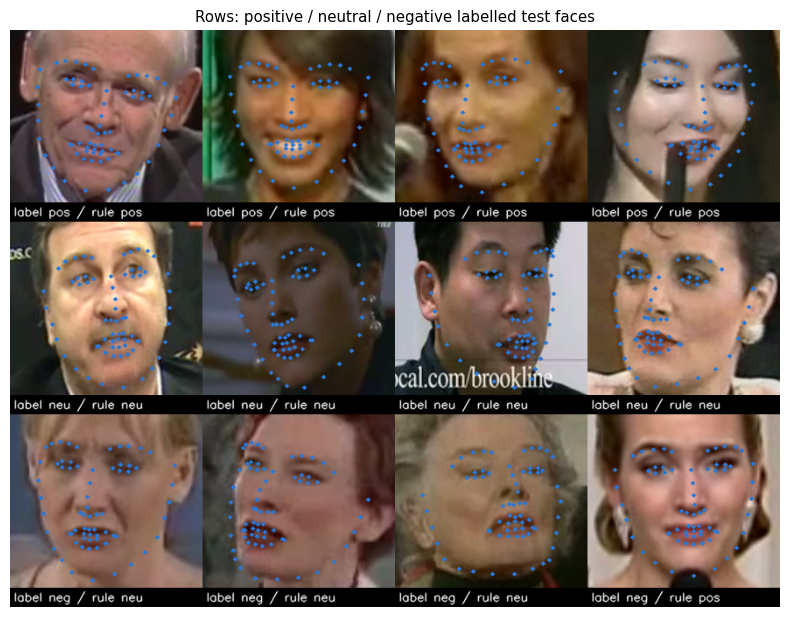

In [11]:
# ===== Cell 8: rule-based emotion: positive / neutral / negative (Task 1.3) =====
CLS = ['negative', 'neutral', 'positive']

def align(kp):
    kp = np.asarray(kp, float)
    d = kp[42:48].mean(0) - kp[36:42].mean(0)
    a = np.arctan2(d[1], d[0]); c, s = np.cos(-a), np.sin(-a)
    return (kp - kp[27]) @ np.array([[c, -s], [s, c]]).T / np.linalg.norm(kp[36] - kp[45])

def cues(kp):
    a = align(kp)
    return np.array([
        a[[51, 57, 62, 66], 1].mean() - a[[48, 54], 1].mean(),          # lift: corners above lip centre
        np.linalg.norm(a[54] - a[48]) / np.linalg.norm(a[16] - a[0]),   # w_face: mouth width / face width
        np.linalg.norm(a[64] - a[60]),                                  # w_inner (analysis only)
        a[36:48, 1].mean() - a[17:27, 1].mean(),                        # brow: brow-to-eye height
        np.linalg.norm(a[22] - a[21])])                                 # gap (analysis only)

def scores(C, mu, sd):
    z = (C - mu) / sd
    return (z[:, 0] + z[:, 1]) / 2, -z[:, 3]

def rule(V, F, T):
    return np.where(V >= T[0], 'positive', np.where((V <= T[1]) | (F >= T[2]), 'negative', 'neutral'))

def macro_f1(y, p):
    f = []
    for c in CLS:
        tp = np.sum((y == c) & (p == c)); fp = np.sum((y != c) & (p == c)); fn = np.sum((y == c) & (p != c))
        f.append(0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f)), dict(zip(CLS, [round(float(v), 3) for v in f]))

def confusion(y, p):
    return pd.DataFrame([[int(np.sum((y == r) & (p == c))) for c in CLS] for r in CLS],
                        index=[f'label {c}' for c in CLS], columns=[f'rule {c}' for c in CLS])

def kappa(y, p):
    po = np.mean(y == p); pe = sum(np.mean(y == c) * np.mean(p == c) for c in CLS)
    return float((po - pe) / (1 - pe))

def sample_clips(csv, n):
    names = list(pd.read_csv(csv).iloc[:, 0]); clips = {}
    for i, nm in enumerate(names):
        clips.setdefault(re.sub(r'\d\.jpg$', '', nm), []).append(i)
    rng = np.random.RandomState(1); keys = sorted(clips); rng.shuffle(keys)
    return [names[int(rng.choice(clips[k]))] for k in keys[:n]]

POS = {'training': [3,7,15,16,23,28,30,36,41,42,43,45,47,48,49,52,53,55,61,81,85,93,102,107,108,110,112,115,117],
       'test': [7,10,15,28,32,35,42,56,61,66,67,68,71,72,73,83,85,86,91,93,94,95,101,102,106,108,121,125,126,127,131]}
NEG = {'training': [2,5,11,56,82,87], 'test': [3,4,49,84,136,149]}
LABELS = {}
for split, csv, n in [('training', TRAIN_CSV, 120), ('test', TEST_CSV, 150)]:
    sel = sample_clips(csv, n)
    LABELS[split] = pd.DataFrame({'image': sel, 'label': ['positive' if i in POS[split] else 'negative' if i in NEG[split]
                                                         else 'neutral' for i in range(n)]})
tr_df = pd.read_csv(TRAIN_CSV); tr_df = tr_df.set_index(tr_df.columns[0])
te_df = pd.read_csv(TEST_CSV);  te_df = te_df.set_index(te_df.columns[0])
gt_kp = lambda df, n: df.loc[n].values.astype(float).reshape(68, 2)
C_all = np.array([cues(gt_kp(tr_df, n)) for n in tr_df.index])
MU, SD = C_all.mean(0), C_all.std(0)
Ltr = LABELS['training']; ytr = Ltr.label.values
Vtr, Ftr = scores(np.array([cues(gt_kp(tr_df, n)) for n in Ltr.image]), MU, SD)
best = (-1, None)
for T in itertools.product(np.arange(0.0, 1.51, 0.05), np.arange(-2.0, -0.49, 0.05), np.arange(0.5, 3.01, 0.1)):
    f = macro_f1(ytr, rule(Vtr, Ftr, T))[0]
    if f > best[0] + 1e-9: best = (f, T)
T = best[1]
Lte = LABELS['test']; yte = Lte.label.values
Vg, Fg = scores(np.array([cues(gt_kp(te_df, n)) for n in Lte.image]), MU, SD)
pg = rule(Vg, Fg, T)

# ---- predicted key points are z-scored with statistics of PREDICTED shapes (held-out val identities),
#      because direct regression shrinks shapes toward the mean face ----
pv, _ = predict(va_ds)
Cp = np.array([cues(k) for k in pv]); MU_P, SD_P = Cp.mean(0), Cp.std(0)

pmap = {n: i for i, n in enumerate(NAMES)}
Vp, Fp = scores(np.array([cues(PRED[pmap[n]]) for n in Lte.image]), MU_P, SD_P)
pp = rule(Vp, Fp, T)

# ---- label-free consistency on ALL 770 test faces: rule(GT key points) vs rule(predicted key points) ----
Va, Fa = scores(np.array([cues(k) for k in GT]), MU, SD)
Vb, Fb = scores(np.array([cues(k) for k in PRED]), MU_P, SD_P)
ea, eb = rule(Va, Fa, T), rule(Vb, Fb, T)

print(f'thresholds (tuned on {len(ytr)} labelled TRAIN faces, GT key points): '
      f'T_pos={T[0]:.2f}  T_neg={T[1]:.2f}  T_frown={T[2]:.2f}   train macro-F1={best[0]:.3f}')
print(f'\nlabelled TEST faces ({len(yte)}) - rule on GT key points:  acc {np.mean(pg == yte):.3f}  macro-F1 {macro_f1(yte, pg)[0]:.3f}  per-class F1 {macro_f1(yte, pg)[1]}')
print(confusion(yte, pg).to_string())
print(f'\nlabelled TEST faces ({len(yte)}) - rule on PREDICTED key points:  acc {np.mean(pp == yte):.3f}  macro-F1 {macro_f1(yte, pp)[0]:.3f}  per-class F1 {macro_f1(yte, pp)[1]}')
print(confusion(yte, pp).to_string())
print(f'\nall {len(ea)} test faces - GT-based vs prediction-based emotion: agreement {np.mean(ea == eb):.3f}  '
      f'Cohen kappa {kappa(ea, eb):.3f}  valence correlation r {np.corrcoef(Va, Vb)[0, 1]:.3f}')
print('cue fidelity corr(GT, pred) [lift, w_face, w_inner, brow, gap]:',
      np.round([np.corrcoef(np.array([cues(k) for k in GT])[:, j], np.array([cues(k) for k in PRED])[:, j])[0, 1] for j in range(5)], 2))

json.dump({'T': list(map(float, T)), 'mu': MU.tolist(), 'sd': SD.tolist(), 'mu_pred': MU_P.tolist(), 'sd_pred': SD_P.tolist()},
          open(f'{OUT}/emotion_params.json', 'w'), indent=1)
pd.concat([LABELS['training'].assign(split='training'), LABELS['test'].assign(split='test')]).to_csv(f'{OUT}/emotion_labels.csv', index=False)

# ---- examples: 4 per class (blue = predicted key points) ----
rows = []
for cls in CLS[::-1]:
    idx = np.where(yte == cls)[0]
    idx = sorted(idx, key=lambda i: pp[i] != cls)[:4]           # correct ones first
    tiles = [draw(Lte.image[i], PRED[pmap[Lte.image[i]]], label=f'label {cls[:3]} / rule {pp[i][:3]}') for i in idx]
    tiles += [np.zeros_like(tiles[0])] * (4 - len(tiles))
    rows.append(np.hstack(tiles))
grid = np.vstack(rows)
cv2.imwrite(f'{FIG}/emotion_examples.jpg', cv2.cvtColor(grid, cv2.COLOR_RGB2BGR))
plt.figure(figsize=(10, 7.5)); plt.imshow(grid); plt.axis('off'); plt.title('Rows: positive / neutral / negative labelled test faces'); plt.show()

In [12]:
# ===== Cell 10: download all outputs =====
import shutil
from google.colab import files
shutil.make_archive('/content/task1_outputs', 'zip', OUT)
files.download('/content/task1_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>